# 0. Setup (Layered architecture)

## Install Neccersary Packages

The following packages are needed for the program:

* `ipywidgets`: For UI
* `mne`: For data processing
* `numpy`
* `python-picard`: Specific method for ICA during Preprocessing



In [1]:
%pip install ipywidgets
%pip install mne
%pip install numpy matplotlib scipy
%pip install python-picard
%pip install pandas 
%pip install xlrd openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


...


[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## UI

Building the UI utilising `ipywidgets`

In [2]:
from ipywidgets import interact, Dropdown, Text, VBox, HBox, Checkbox, IntSlider

fileUpload = Text(value='data.bdf', description='File Path:')
labelUpload = Text(value='data.xls', description='File Path:')
downsampleOnOff = Checkbox(value=True, description='Downsample')
downsampleDropdown = Dropdown(options=['128', '256', '512'], value='128', description='Downsample Rate:')
bandpassOnOff = Checkbox(value=True, description='Bandpass Filter')
icaMethod = Dropdown(options=['fastica', 'infomax', 'picard'], value='picard', description='ICA Method:')
icaOnOff = Checkbox(value=False, description='ICA')
fastICA = Checkbox(value=True, description='ICA after Downsample')


ui = VBox([
    HBox([fileUpload, labelUpload]),
    HBox([downsampleOnOff, downsampleDropdown]),
    bandpassOnOff,
    HBox([icaOnOff,fastICA, icaMethod])
])

# things to add: FastICA (done after downsample)

In [3]:
display(ui)

# 1. Classes

In [4]:
import mne
import pandas as pd
from scipy.signal import decimate
from scipy.fft import rfft, rfftfreq
import numpy as np
from tqdm.auto import tqdm

RANDSEED = 52

### 1.1 Dataloader

In [5]:
class Dataloader:
  def getData(self, fileUpload):
    raw = mne.io.read_raw_bdf(fileUpload, preload=True)
    #rawcopy = raw.copy().pick(mne.pick_types(raw.info, eeg=True)) This should work, but since DEAP doesnt label thier eeg channels as eeg, we have to brute force delete the non eeg channels (the next line)
    rawcopy = raw.drop_channels(raw.ch_names[32:47])

    events = mne.find_events(raw, stim_channel="Status", initial_event=True) #events comes as 3 columnes (sample Index, prev event code, event code), these are used for segmenting
    # rawcopy = rawcopy.pick('eeg') #removing the status column as it isnt needed anymore
    df = rawcopy.to_data_frame()
    return rawcopy, events, df

  def getLabels(self, labelUpload, particpant):
    df = pd.read_excel(labelUpload)
    valencedf = df[['Participant_id','Valence']]
    valence = valencedf[valencedf['Participant_id'] == particpant]    #just getting the first particpant while testing
    return valence


### 1.2 Preprocess

In [6]:
class Preprocessing:
  def __init__(self, icaMethod, randSeed, nComponents = 0.999999):
    self.ica = mne.preprocessing.ICA(nComponents, random_state=randSeed, max_iter='auto', method = icaMethod.value)

  def preprocess(self, raw, downsampleTrue, downsamplerate, bandpassTrue, icaTrue, icaMethod,fastICA, events):
    rawCopy = raw.copy()

    rawCopy = rawCopy.filter(l_freq=1.5, h_freq=None) # low frequency drifts, gets rid of all freq under 1.5. this does effect the delta band...

    if(bandpassTrue == True): #bandpass True
      rawCopy = rawCopy.filter(l_freq=4, h_freq=45) #range 4 - 45 comes from the bandpass filter that deap use. The top range of the Gamma band is around 45Hz so we dont want anything higher
      if(icaTrue == True): #ICA AND bandpass True
        self.ica.fit(rawCopy)
        rawCopy = self.ica.apply(rawCopy.copy())
    else:
      if(icaTrue == True): #ICA AND bandpass True
        self.ica.fit(rawCopy)
        rawCopy = self.ica.apply(rawCopy.copy())

    if(downsampleTrue == True): #downsample
      rawCopy = rawCopy.resample(sfreq=int(downsamplerate))
      if(fastICA == True): #fast ICA
        self.ica.fit(rawCopy)
        rawCopy = self.ica.apply(rawCopy.copy())

    df = rawCopy.to_data_frame()
    return rawCopy, df

### 1.3 Segmentation

In [7]:
class Segmentation:

  def getEpochs(self, raw, events, eventId, labels):
    tmin = -3.0         # start exactly at event onset
    tmax = 60       # 60 seconds long (video length)
    baselineTmin = -3.0
    baselineTmax = 0.0
    events = mne.find_events(raw, stim_channel="Status", initial_event=True)
    sfreq = raw.info['sfreq']
    n_samples = raw.n_times
    first_event_sample = events[0, 0]
    last_event_sample = events[-1, 0]

    print("Start buffer (s):", first_event_sample / sfreq)
    print("End buffer (s):", (n_samples - last_event_sample) / sfreq)
    epochs = mne.Epochs(
      raw,
      events,
      eventId,
      tmin=tmin,
      tmax=tmax,
      reject= None,
      flat= None,
      baseline=(baselineTmin, baselineTmax),
      preload=True,)
    # epochs.plot(n_epochs=10, events=True)
    epochsNumpy = epochs.get_data()

    labels_array = np.array(labels)
    labelsNotDropped = labels_array[epochs.events[:, 2] - 1]  # event IDs start at 1



    return epochsNumpy,labelsNotDropped

### 1.4 Feature Extraction


In [8]:
class FeatureExtraction:
    def __init__(self):
        self.bands = {
            'delta': (0.5, 4),
            'theta': (4, 7),
            'alpha': (7, 12),
            'beta':  (12, 30),
            'gamma': (30, 80)
        }

    def fftBandPowers(self, data, label, samplingRate, windowSizeSec=1.0, overlap=0.5):
        step = int(windowSizeSec * samplingRate * (1 - overlap))
        winLength = int(windowSizeSec * samplingRate)
        nWindows = (data.shape[-1] - winLength) // step + 1
        times = np.arange(nWindows) * step / samplingRate

        X = []
        for w in range(nWindows):
            start = w * step
            end = start + winLength
            seg = data[..., start:end]
            yf = np.abs(rfft(seg, axis=-1)) ** 2
            xf = rfftfreq(winLength, 1 / samplingRate)

            features = [np.sum(yf[..., (xf >= low) & (xf <= high)], axis=-1) for low, high in self.bands.values()]

            for low, high in self.bands.values():
                idx = (xf >= low) & (xf <= high)
                power = np.sum(yf[..., idx], axis=-1)
                features.append(power)

            X.append(np.stack(features, axis=-1))

        if not X:  # no windows
          return np.array([]), np.array([]), np.array([])

        X = np.stack(X, axis=0)  # (windows, channels, bands)
        labels_repeated = np.repeat(label, nWindows)
        return times, X, labels_repeated

    def extract(self, segments, labels, samplingRate, windowSizeSec=1.0, overlap=0.5):
        allX, allTimes, allLabels = [], [], []
        # if len(labels) != len(segments):
          # raise ValueError(f"Labels length {len(labels)} does not match segments length {len(segments)}")
        if len(segments) == 0:
          return np.array([]), [], np.array([])
        for i, seg in enumerate(segments):
            times, bandPowers, repeated_labels = self.fftBandPowers(seg, labels[i], samplingRate, windowSizeSec, overlap)
            if bandPowers.size == 0:
              continue

            bandPowers = bandPowers.reshape(bandPowers.shape[0], -1)  # flatten channels x bands
            allX.append(bandPowers)
            allTimes.extend(times)
            allLabels.extend(repeated_labels)
        if not allX:
          return np.array([]), np.array([]), np.array([])  # No data to concatenate, return empty arrays or None as appropriate

        allX = np.vstack(allX)
        allTimes = np.array(allTimes)
        allLabels = np.array(allLabels)
        return allX, allTimes, allLabels


#2. Pipeline

### 2.1 Constructors


In [9]:
dl = Dataloader()
preProcessor = Preprocessing(randSeed = RANDSEED, nComponents = 0.999, icaMethod = icaMethod)
segmenter = Segmentation()
fE = FeatureExtraction()


### 2.2 Dataflow

  0%|          | 0/15 [00:00<?, ?it/s]

Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s01.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1980927  =      0.000 ...  3868.998 secs...
Finding events on: Status
13761 events found on stim channel Status
Event IDs: [    1     2     3     4     5     6     7 65536]
[Dataloader] Raw shape: (33, 1980928), sfreq: 512.0


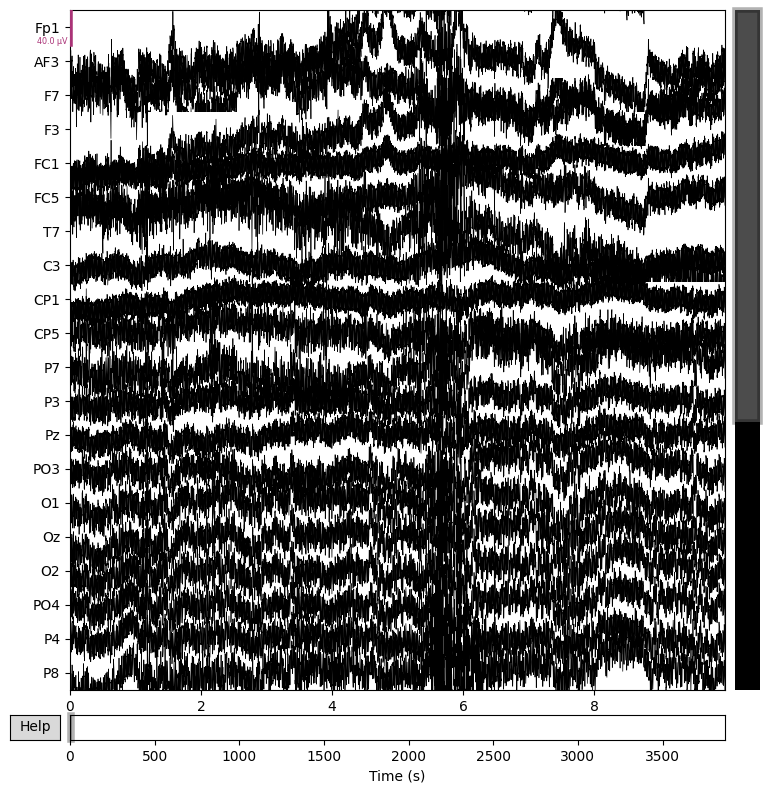

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 15 components
Fitting ICA took 222.9s.


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\picard\solver.py:213: UserWarning: Picard did not converge. Final gradient norm : 6.088e-07. Requested tolerance : 1e-07. Consider increasing the number of iterations or the tolerance.
  warnings.warn('Picard did not converge. Final gradient norm : %.4g.'


Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 495232)


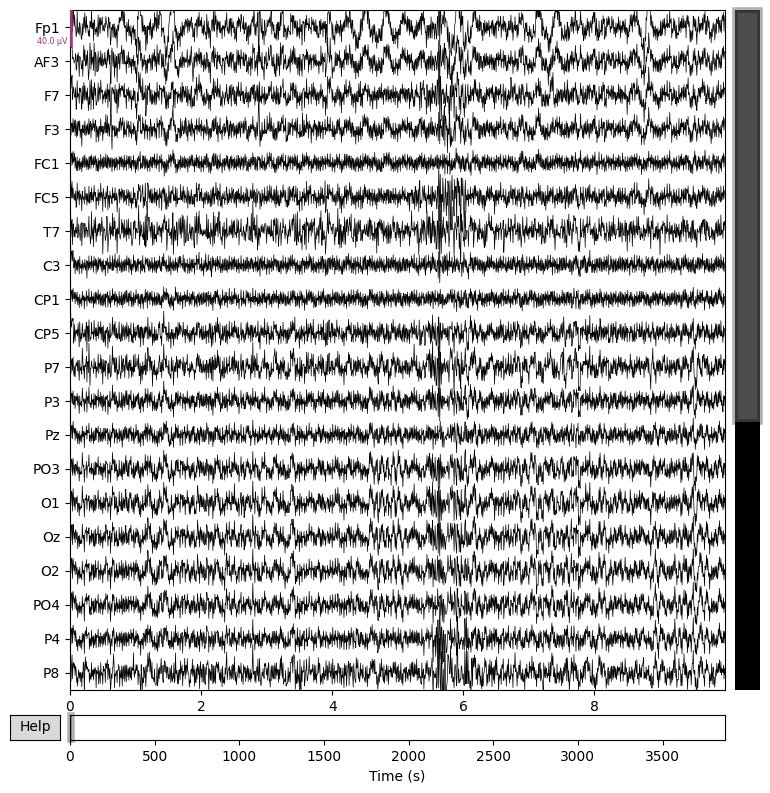

Finding events on: Status
299 events found on stim channel Status
Event IDs: [    1     2     3     4     5     6     7 65536]
Start buffer (s): 0.0
End buffer (s): 195.78125
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s02.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1895935  =      0.000 ...  3702.998 secs...
Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1895936), sfreq: 512.0


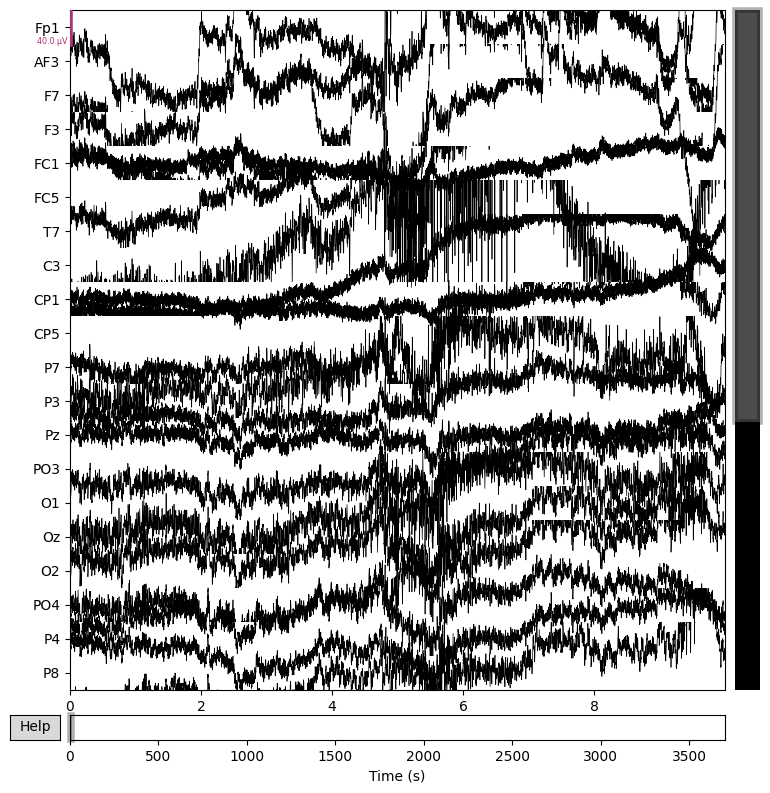

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 6 components
Fitting ICA took 46.6s.
Applying ICA to Raw instance
    Transforming to ICA space (6 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 473984)


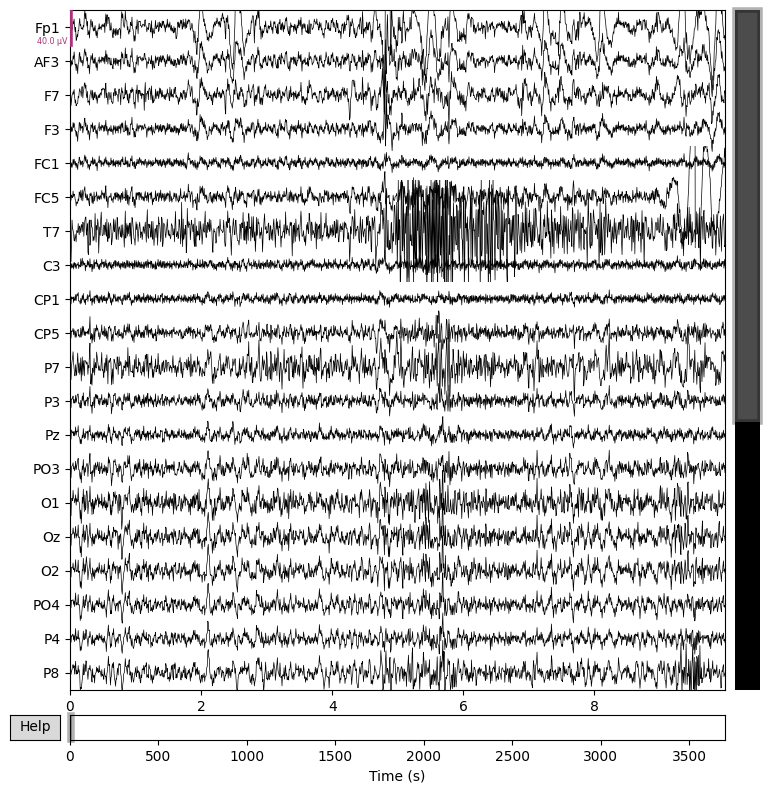

Finding events on: Status
287 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 118.3515625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s03.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1989119  =      0.000 ...  3884.998 secs...
Finding events on: Status
285 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1989120), sfreq: 512.0


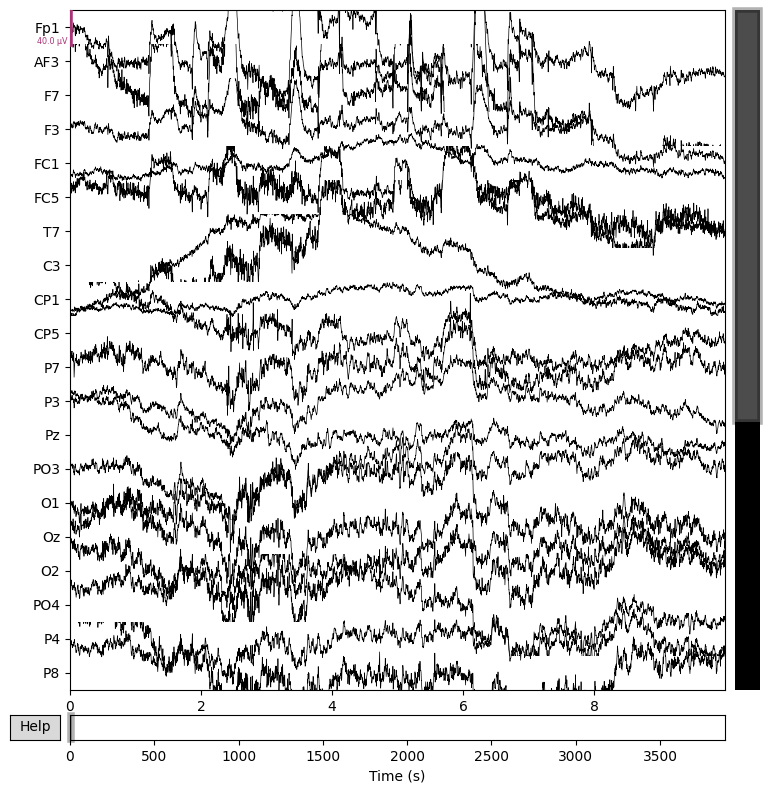

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\picard\solver.py:213: UserWarning: Picard did not converge. Final gradient norm : 4.62e-05. Requested tolerance : 1e-07. Consider increasing the number of iterations or the tolerance.
  warnings.warn('Picard did not converge. Final gradient norm : %.4g.'


Fitting ICA took 339.7s.
Applying ICA to Raw instance
    Transforming to ICA space (24 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 497280)


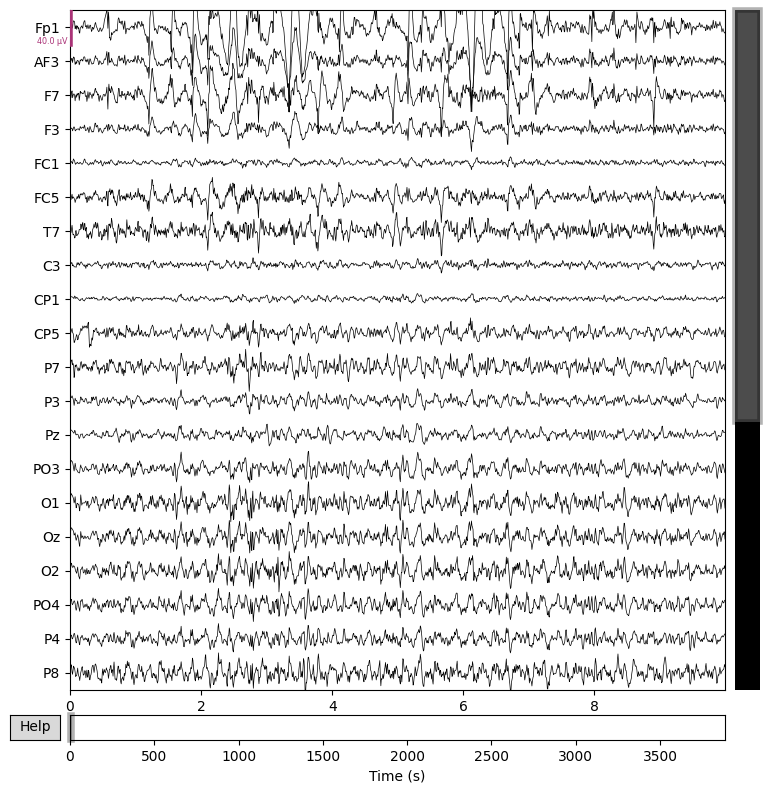

Finding events on: Status
285 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 79.7421875
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s04.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1690111  =      0.000 ...  3300.998 secs...
Finding events on: Status
287 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1690112), sfreq: 512.0


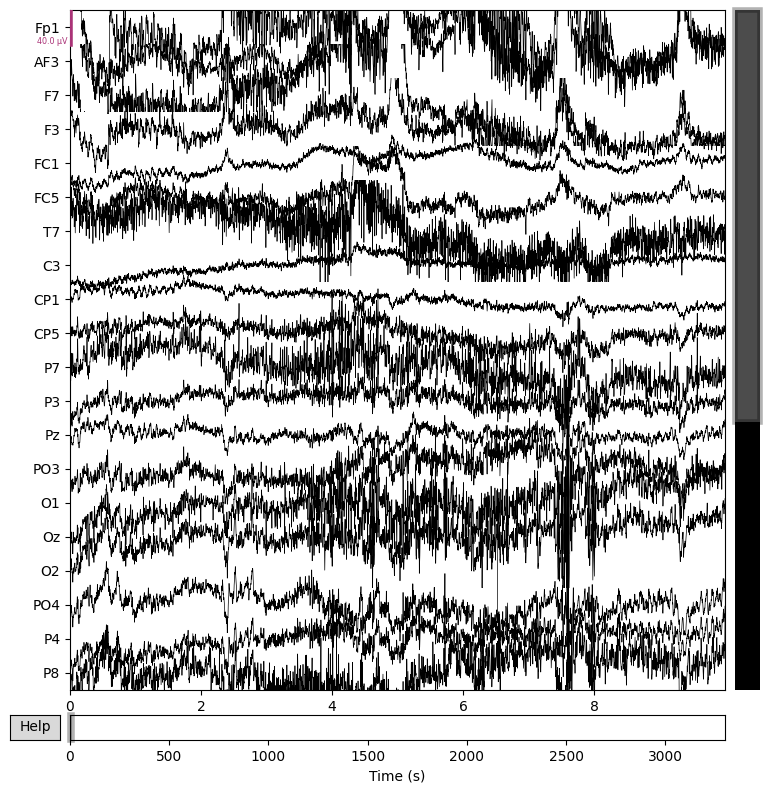

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 29 components
Fitting ICA took 77.1s.
Applying ICA to Raw instance
    Transforming to ICA space (29 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 422528)


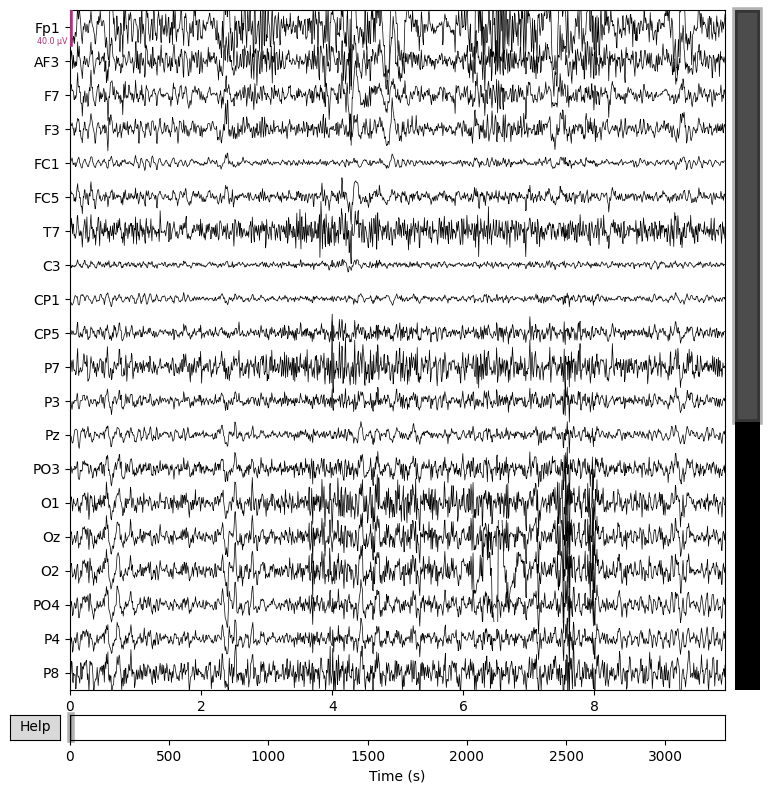

Finding events on: Status
286 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 40.9921875
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s05.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2004991  =      0.000 ...  3915.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 2004992), sfreq: 512.0


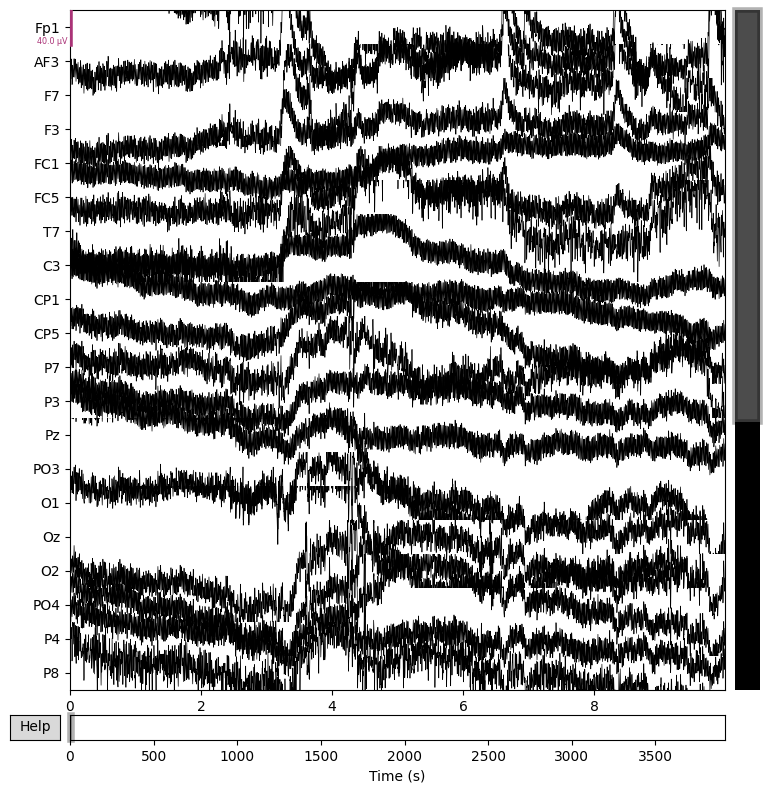

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

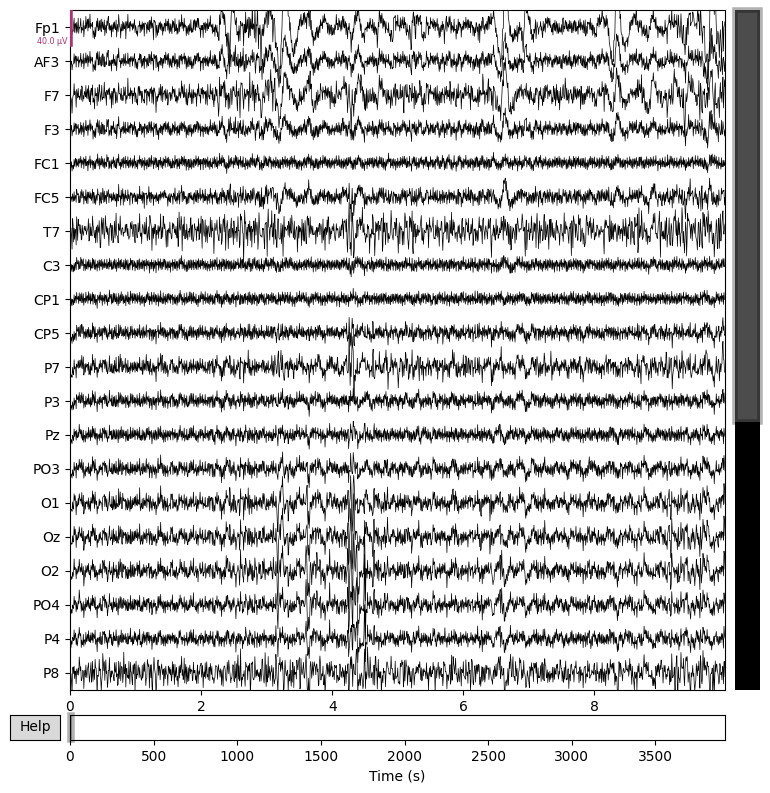

Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 87.0625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s06.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1836031  =      0.000 ...  3585.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1836032), sfreq: 512.0


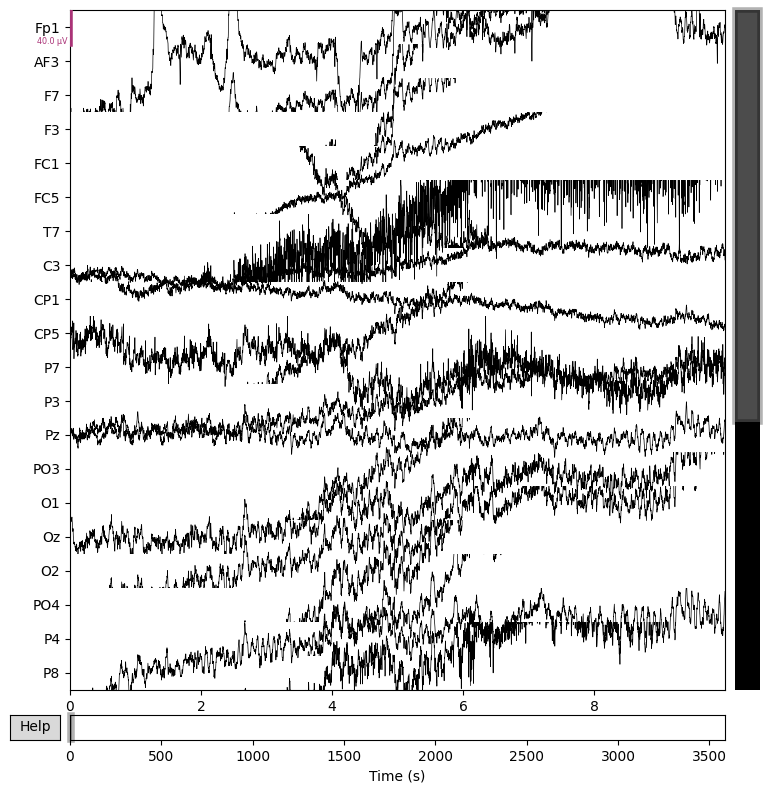

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 30 components
Fitting ICA took 96.2s.
Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 459008)


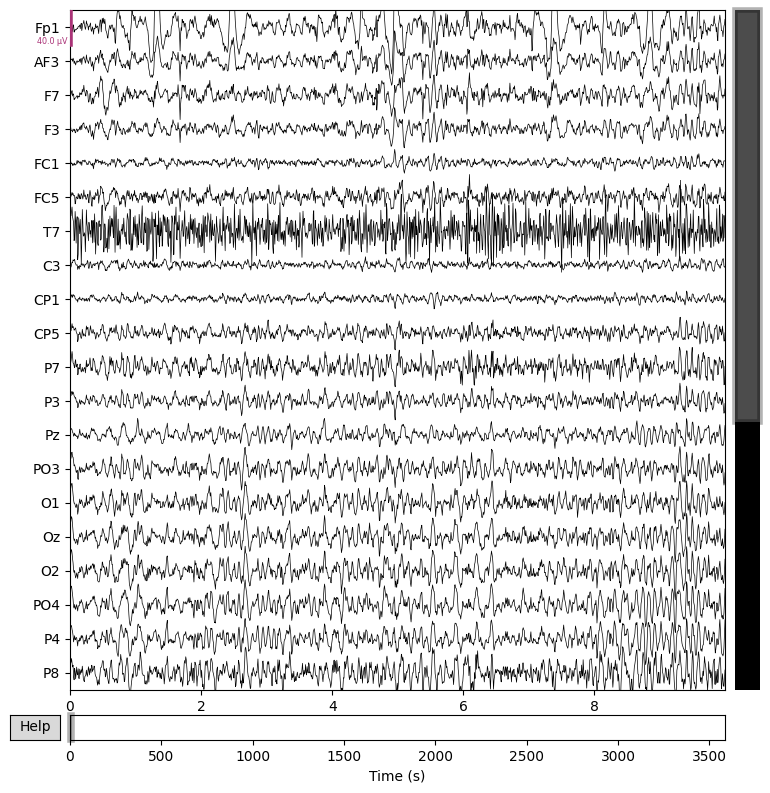

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 25.7109375
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s07.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1828351  =      0.000 ...  3570.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1828352), sfreq: 512.0


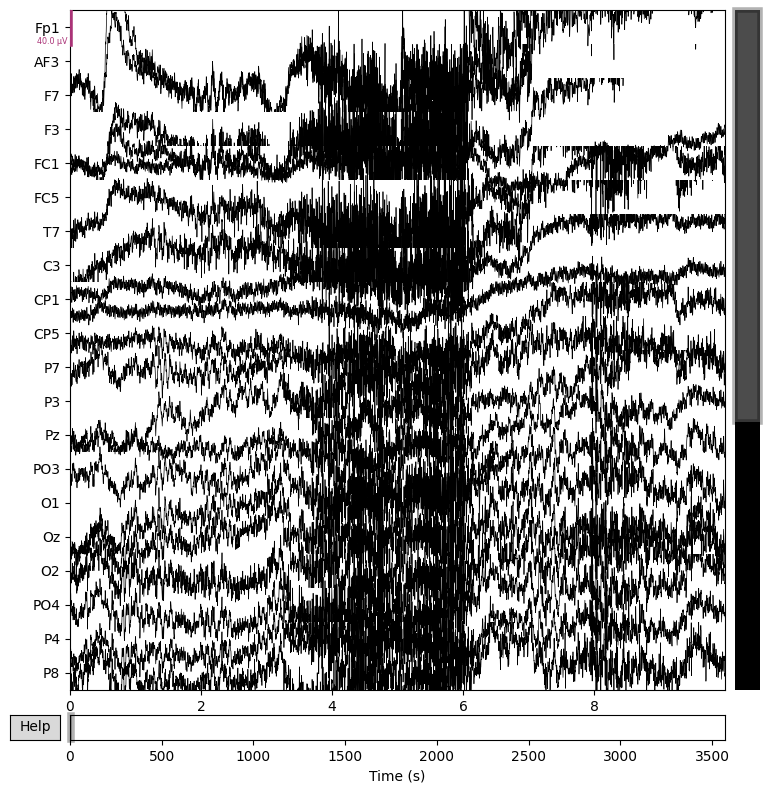

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 31 components
Fitting ICA took 128.8s.
Applying ICA to Raw instance
    Transforming to ICA space (31 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 457088)


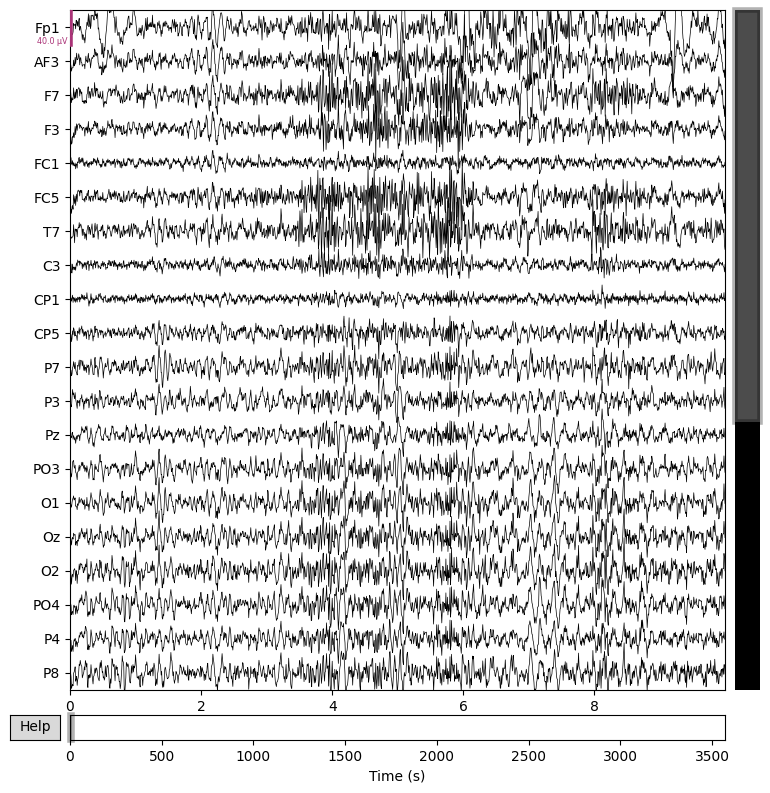

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 17.421875
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s08.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1800703  =      0.000 ...  3516.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1800704), sfreq: 512.0


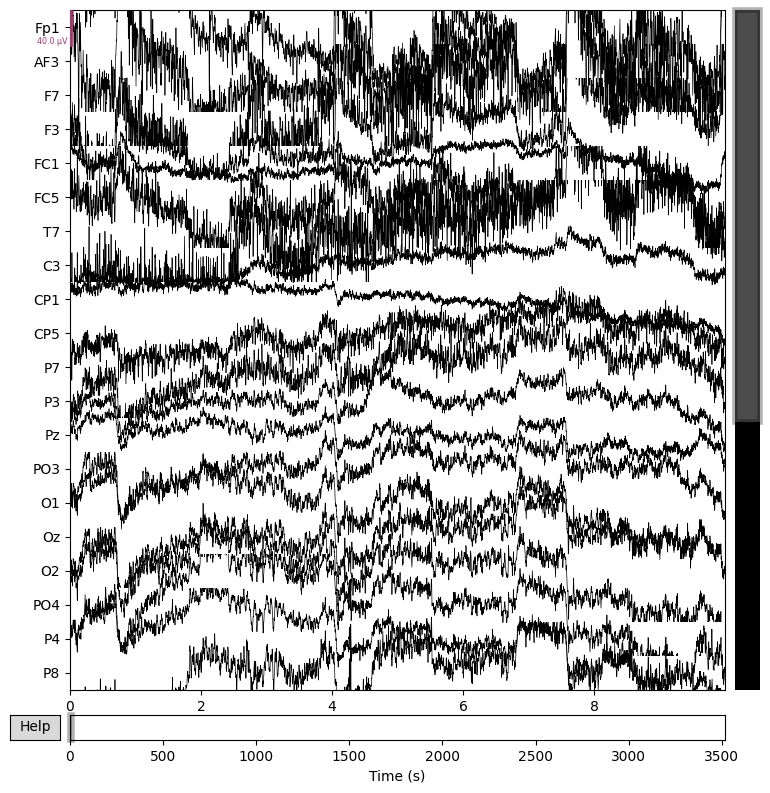

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 16 components
Fitting ICA took 45.0s.
Applying ICA to Raw instance
    Transforming to ICA space (16 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 450176)


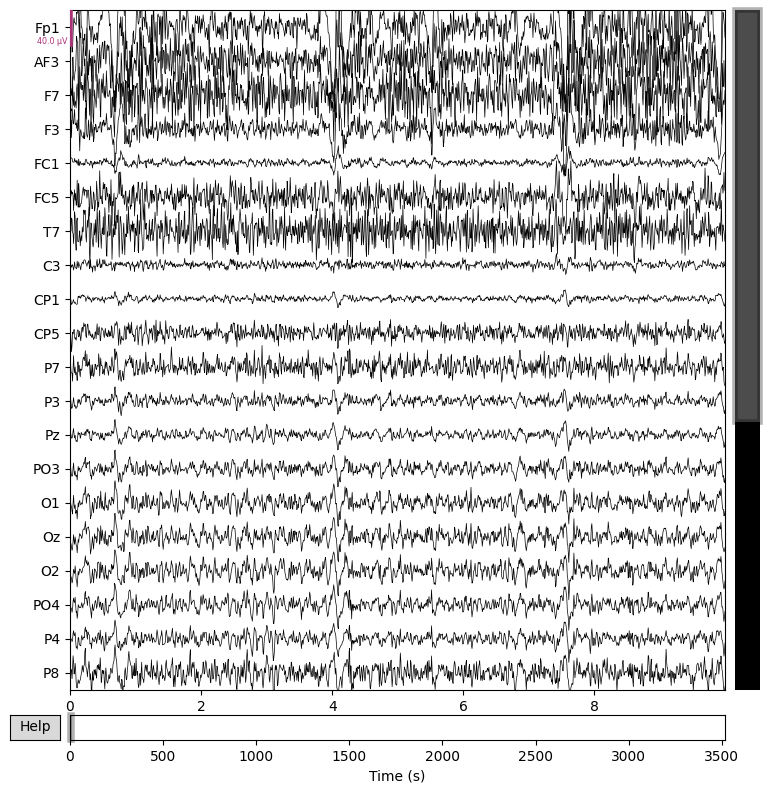

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 91.625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s09.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1928703  =      0.000 ...  3766.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1928704), sfreq: 512.0


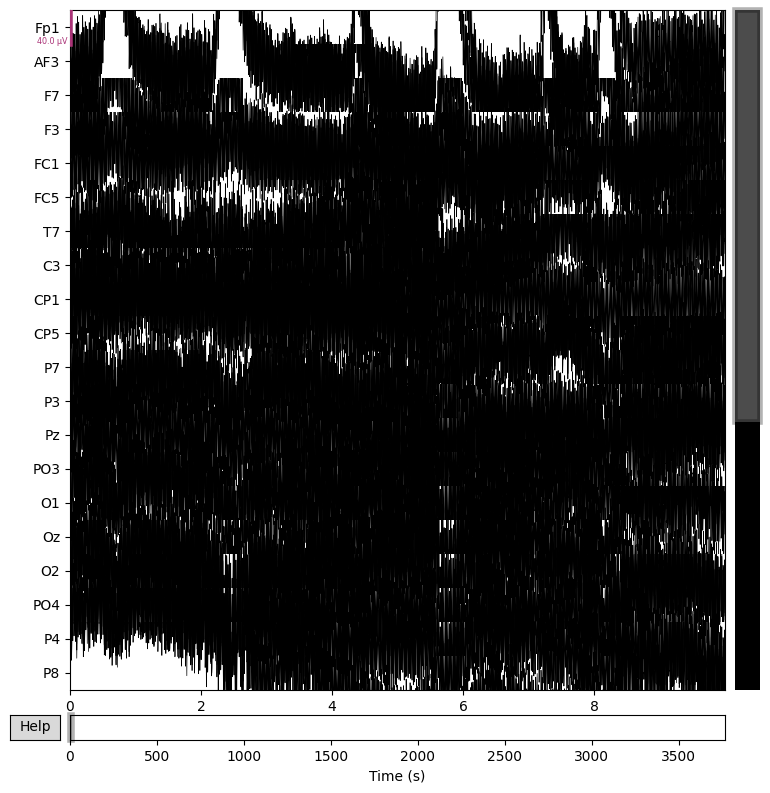

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 28 components
Fitting ICA took 112.6s.
Applying ICA to Raw instance
    Transforming to ICA space (28 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 482176)


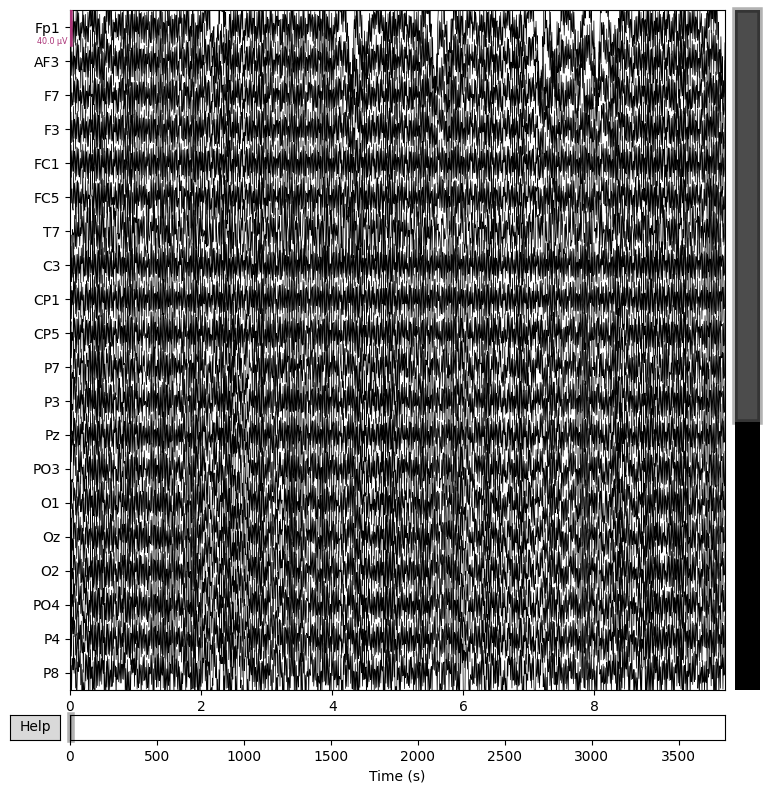

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 16.7265625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s10.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1798143  =      0.000 ...  3511.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1798144), sfreq: 512.0


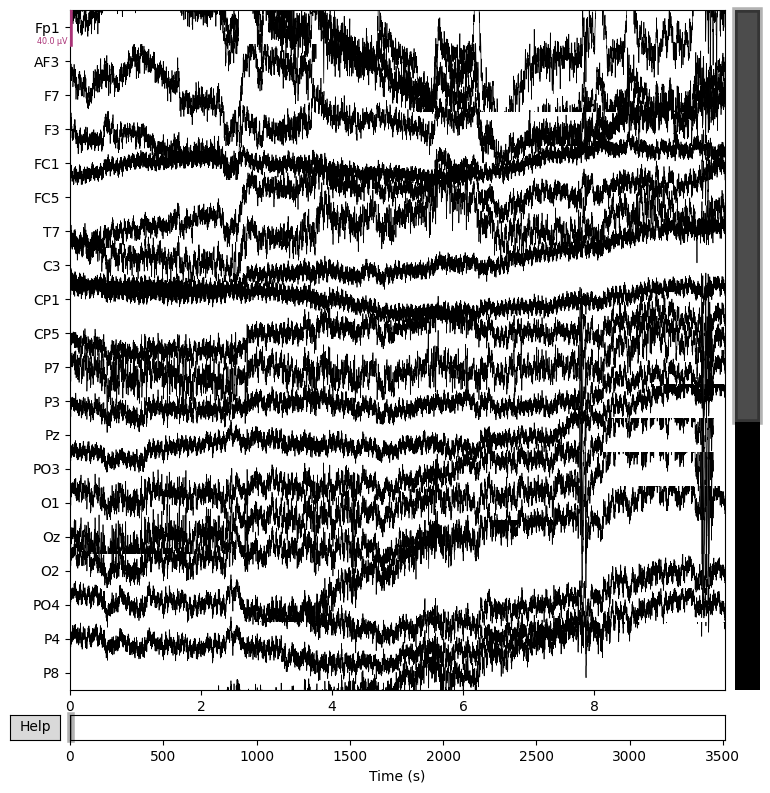

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

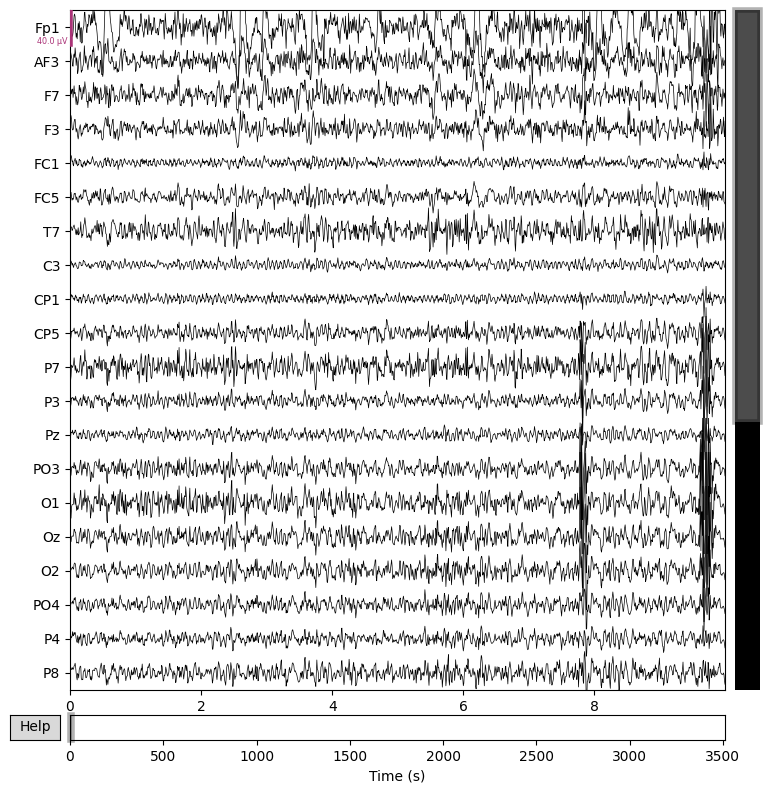

Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 22.3203125
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s11.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2130431  =      0.000 ...  4160.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 2130432), sfreq: 512.0


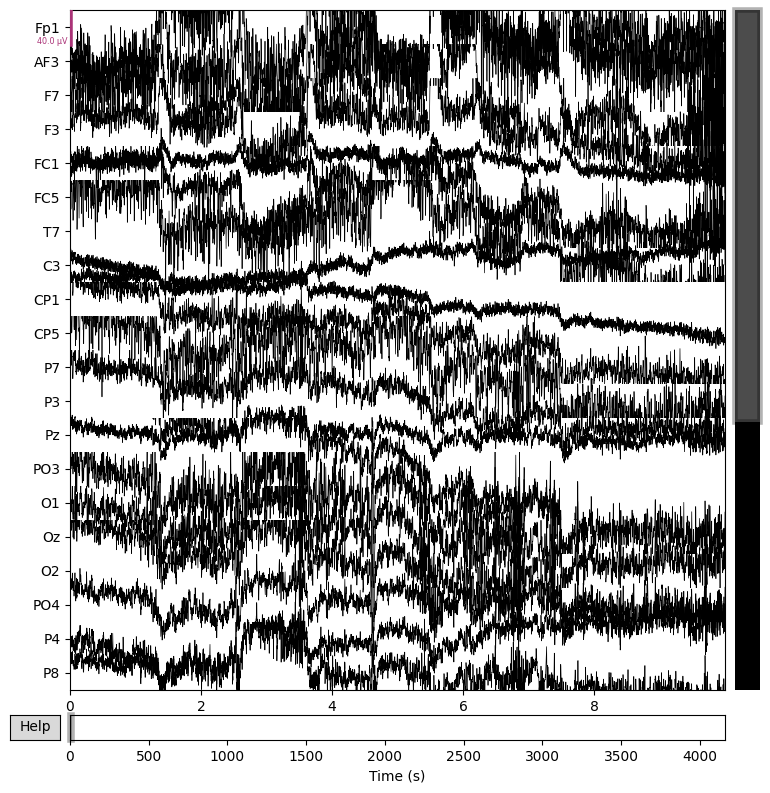

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 30 components
Fitting ICA took 100.6s.
Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 532608)


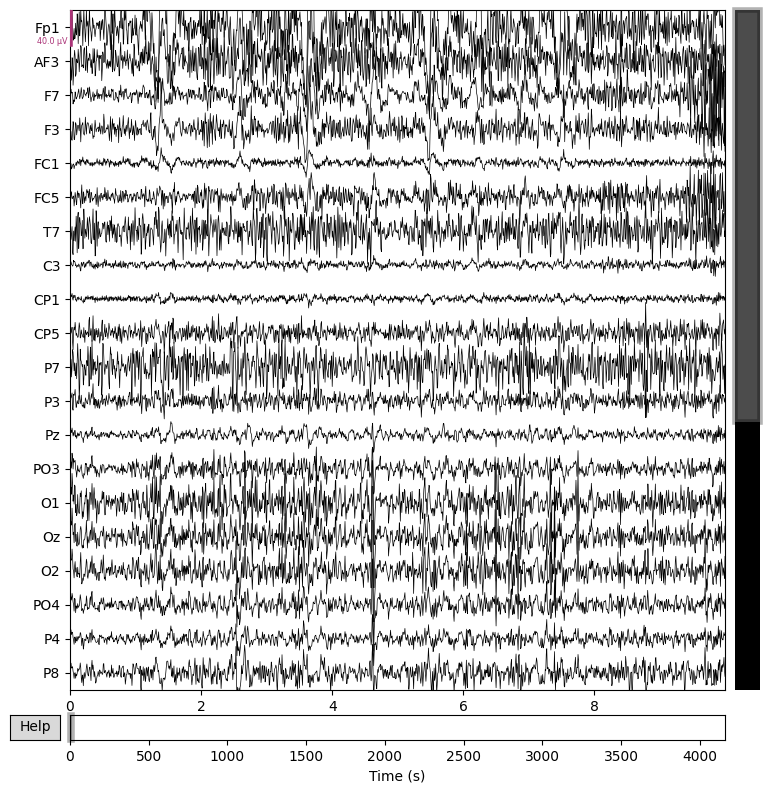

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 26.890625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s12.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1790975  =      0.000 ...  3497.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1790976), sfreq: 512.0


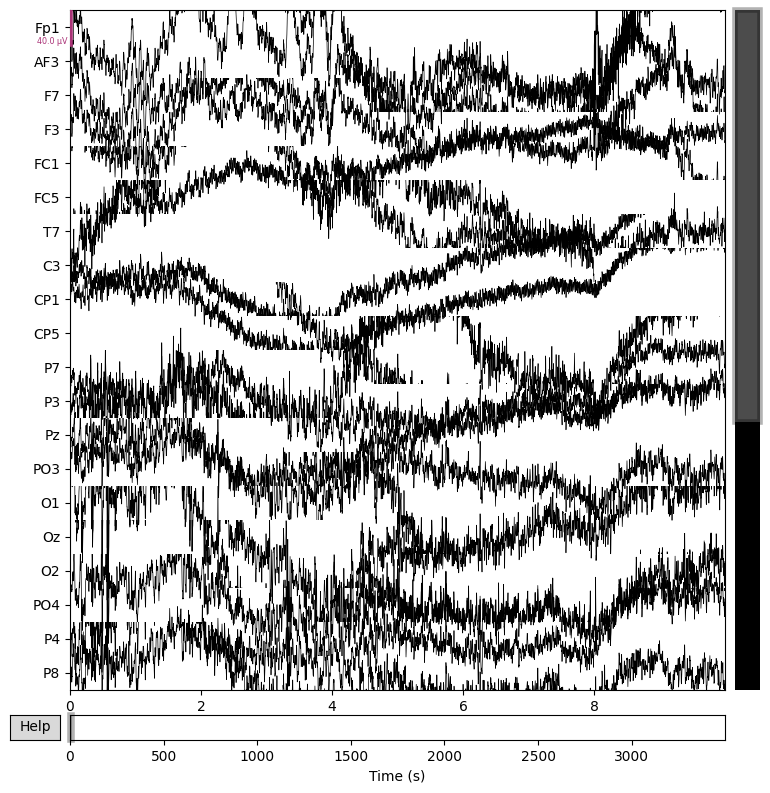

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 30 components
Fitting ICA took 183.9s.
Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 447744)


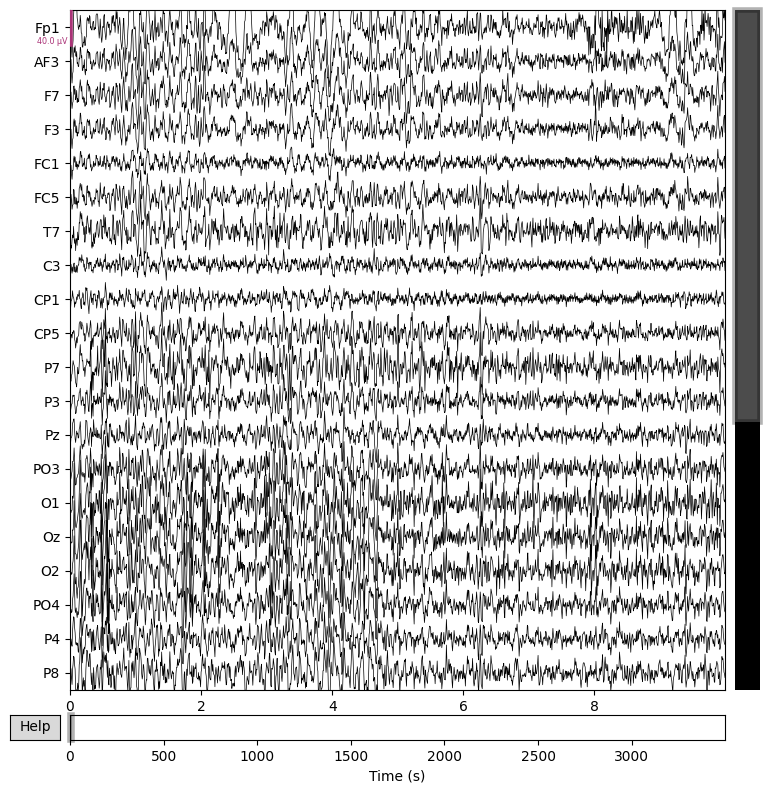

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 18.234375
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s13.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1900031  =      0.000 ...  3710.998 secs...
Finding events on: Status
290 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 1900032), sfreq: 512.0


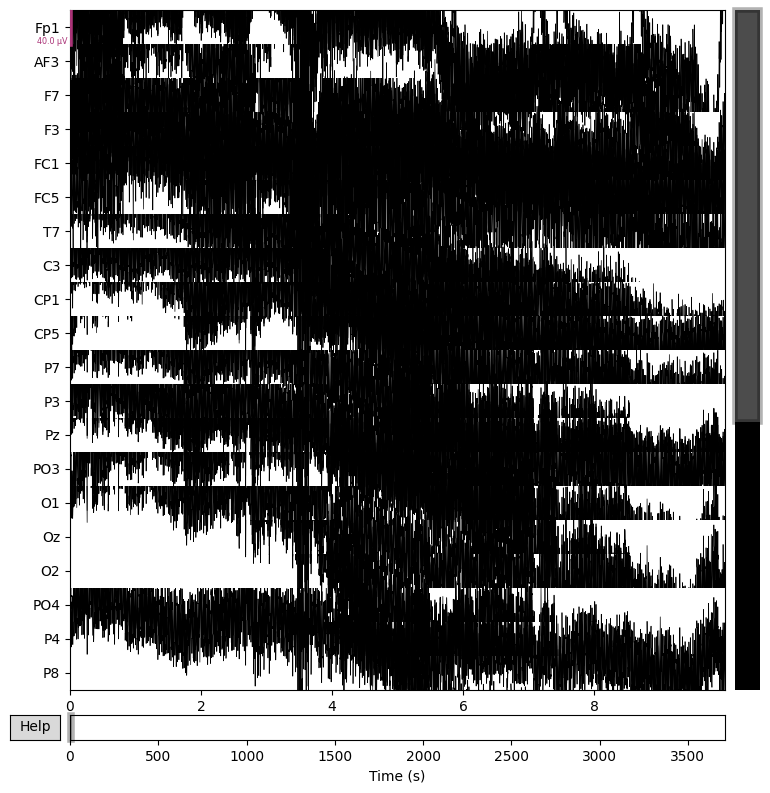

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

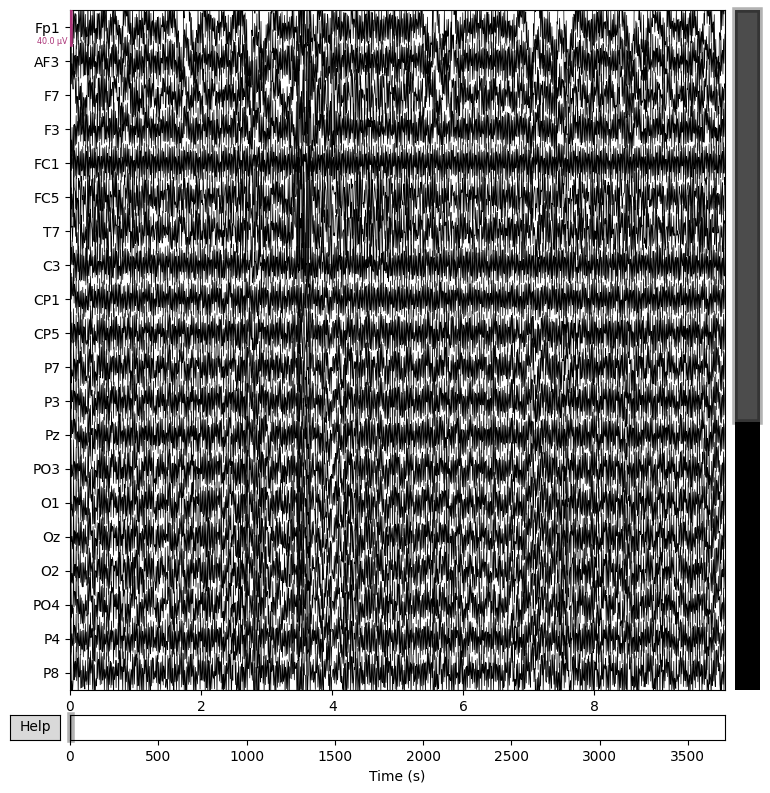

Finding events on: Status
290 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 29.2109375
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s14.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2015743  =      0.000 ...  3936.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 2015744), sfreq: 512.0


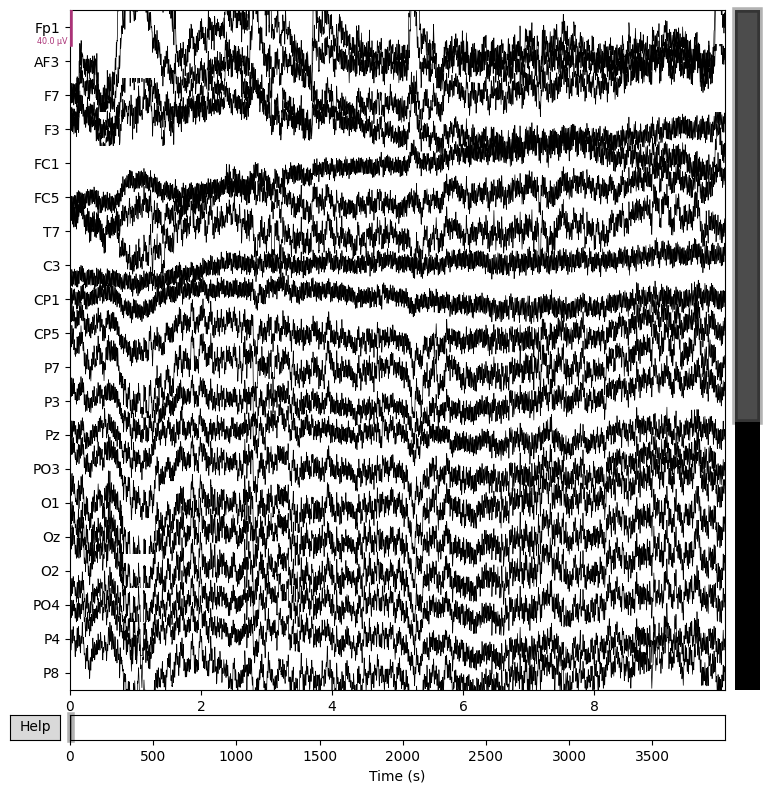

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

C:\Users\User\AppData\Local\Temp\ipykernel_7448\1247015072.py:21: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by explained variance: 10 components
Fitting ICA took 62.6s.
Applying ICA to Raw instance
    Transforming to ICA space (10 components)
    Zeroing out 0 ICA components
    Projecting back using 32 PCA components
-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: (33, 503936)


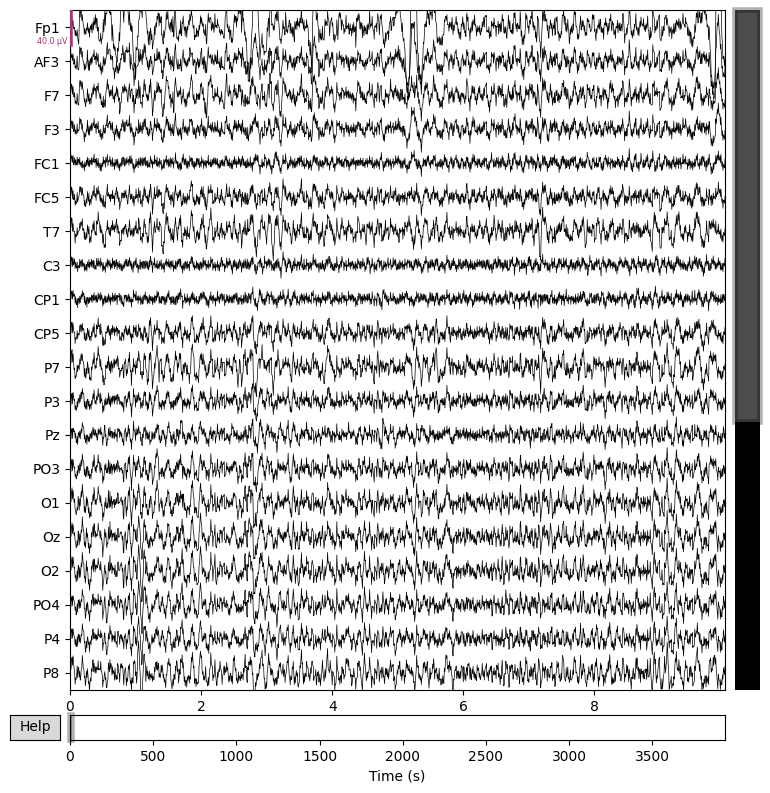

Finding events on: Status
288 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 52.2890625
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
Extracting EDF parameters from c:\Users\User\Desktop\Uni\Comp4092 Thesis\notebook saves\s15.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2084863  =      0.000 ...  4071.998 secs...
Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
[Dataloader] Raw shape: (33, 2084864), sfreq: 512.0


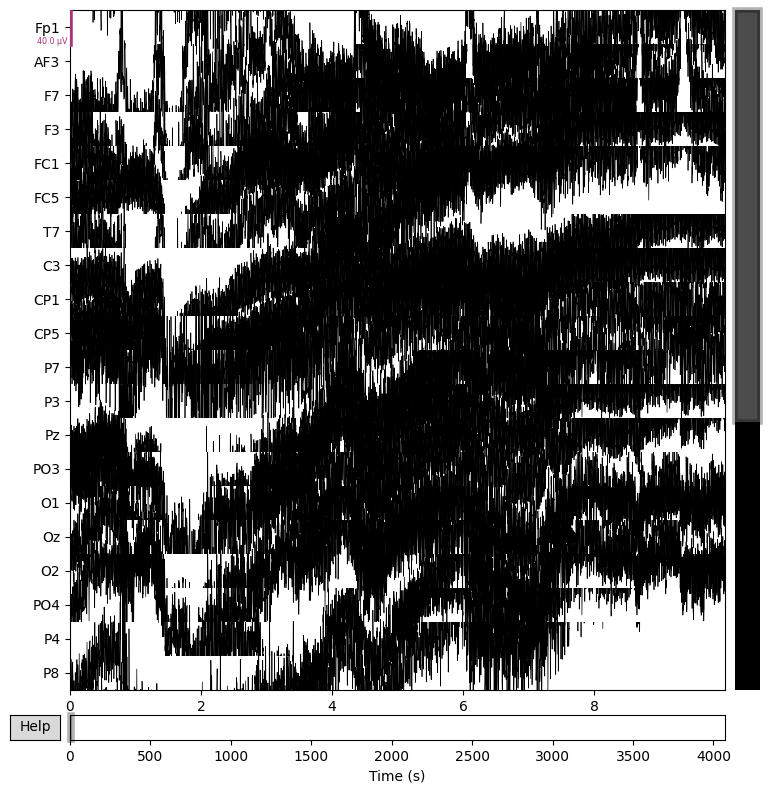

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 4 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 4.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 3.00 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 845 samples

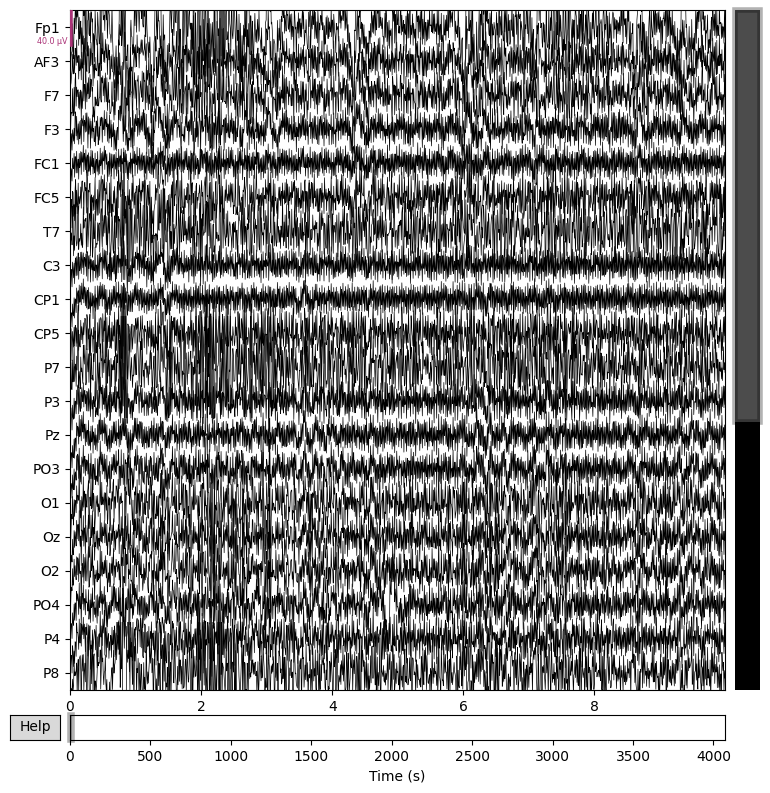

Finding events on: Status
289 events found on stim channel Status
Event IDs: [    1     2     3     4     5     7 65536]
Start buffer (s): 0.0
End buffer (s): 476.09375
Not setting metadata
40 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 40 events and 8065 original time points ...
0 bad epochs dropped
Epoch shape: 2

 SIZE OF X = (125, 13200)
[Concat Check] Participant 0: (125, 13200)
[Concat Check] Participant 1: (125, 13200)
[Concat Check] Participant 2: (125, 13200)
[Concat Check] Participant 3: (125, 13200)
[Concat Check] Participant 4: (125, 13200)
[Concat Check] Participant 5: (125, 13200)
[Concat Check] Participant 6: (125, 13200)
[Concat Check] Participant 7: (125, 13200)
[Concat Check] Participant 8: (125, 13200)
[Concat Check] Participant 9: (125, 13200)
[Concat Check] Participant 10: (125, 13200)
[Concat Check] Participant 11: (125, 13200)
[Concat Check] Participant 12: (125, 13200)
[Concat Che

In [12]:
allX = []
allYLabels = []


for i in tqdm(range(1, 16)):  # participants 1 to 22
  fileUpload = f"s{i:02d}.bdf"
  raw, events, df = dl.getData(fileUpload) # events is shape (13761, 3), df is (1980928, 34)

  print(f"[Dataloader] Raw shape: {raw.get_data().shape}, sfreq: {raw.info['sfreq']}")
  labels = dl.getLabels(labelUpload.value, particpant = i) # labels are (particpant id, valence float score from 1 - 9) 40 values for 40 videos
  raw.plot()
  praw, df = preProcessor.preprocess(raw = raw,  #(495232, 33)
                                    downsampleTrue = downsampleOnOff.value,
                                    downsamplerate = downsampleDropdown.value,
                                    bandpassTrue = bandpassOnOff.value,
                                    icaTrue = icaOnOff.value,
                                    icaMethod = icaMethod,
                                    fastICA = fastICA.value,
                                    events = events)
  print(f"-----------------------------------------------------------------[Preprocessing] After filtering/downsampling: {praw.get_data().shape}")
  praw.plot()
  epochs = segmenter.getEpochs(raw = praw, events = events, eventId= 4, labels = labels) #shape is like (num of epochs, channels, time sample for each channel)
  print(f"Epoch shape: {len(epochs)}")
  X, xTime, ylabels = fE.extract(segments = epochs, labels = labels['Valence'].to_numpy(), samplingRate = praw.info['sfreq'])

  allX.append(X)
  allYLabels.append(ylabels)
  print(f"\n SIZE OF X = {X.shape}")

for i, X in enumerate(allX):
    print(f"[Concat Check] Participant {i}: {X.shape}")
allX = np.vstack(allX)
allYLabels = np.hstack(allYLabels)

In [ ]:
# for i in range(0,125):
print(len(allX[6][0]))


In [ ]:
allX = np.vstack(allX)
allYLabels = np.hstack(allYLabels)

In [ ]:
raw, events, df = dl.getData(fileUpload) # events is shape (13761, 3), df is (1980928, 34)
labels = dl.getLabels(labelUpload.value, particpant=14) # labels are (particpant id, valence float score from 1 - 9) 40 values for 40 videos
raw, df = preProcessor.preprocess(raw = raw,  #(495232, 33)
                                  downsampleTrue = downsampleOnOff.value,
                                  downsamplerate = downsampleDropdown.value,
                                  bandpassTrue = bandpassOnOff.value,
                                  icaTrue = icaOnOff.value,
                                  icaMethod = icaMethod,
                                  fastICA = fastICA.value,
                                  events = events)
epochs = segmenter.getEpochs(raw = raw, events = events, eventId= 4) #shape is like (num of epochs, channels, time sample for each channel)
X, xTime, ylabels = fE.extract(segments = epochs, labels = labels['Valence'].to_numpy(), samplingRate = raw.info['sfreq'])

In [ ]:
X_svm = np.concatenate(allX, axis=0)      # combine all samples
len(X_svm)

In [ ]:
allX

In [ ]:
storeX = allX
storeY = allYLabels
storeX

In [ ]:
allX

In [13]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report


# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(allX)

# pca = PCA(n_components=0.95)  # keep 95% variance
# X_pca = pca.fit_transform(allX)

y_discrete = (allYLabels >= 5).astype(int)
X_train, X_test, y_train, y_test = train_test_split(allX, y_discrete, test_size=0.2, random_state=42)

svm_clf = SVC(C=10, kernel='rbf', gamma='scale')

svm_clf.fit(X_train, y_train)

y_pred = svm_clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred) # binary classification
f1 = f1_score(y_test, y_pred) # for binary classification
report = classification_report(y_test, y_pred)

print(f"SVM: Accuracy: {acc:.4f}%, Recall :{recall:.4f}%, F1: {f1:.4f}%")
# print(f"Test Accuracy: {acc:.4f}%")

SVM: Accuracy: 0.5467%, Recall :0.0173%, F1: 0.0341%


In [14]:
from sklearn.neighbors import KNeighborsClassifier # or KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler # For data scaling
from sklearn.metrics import accuracy_score # For evaluating classification models

  # Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(allX, y_discrete, test_size=0.3, random_state=42)

# Scale the data (important for distance-based algorithms like KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=2)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

kaccuracy = accuracy_score(y_test, y_pred)
krecall = recall_score(y_test, y_pred) # binary classification
kf1 = f1_score(y_test, y_pred) # for binary classification
kreport = classification_report(y_test, y_pred)

print(f"KNN: Accuracy: {kaccuracy:.4f}%, Recall :{krecall:.4f}%, F1: {kf1:.4f}%")
# print(f"Model Accuracy: {accuracy}")

KNN: Accuracy: 0.9840%, Recall :0.9809%, F1: 0.9828%


In [15]:
from sklearn.ensemble import RandomForestClassifier
np.unique(y_discrete, return_counts=True)

# Initialize
rf_clf = RandomForestClassifier(
    n_estimators=100,      # number of trees
    max_depth=10,        # let trees grow fully
    random_state=42,
    n_jobs=-1              # use all CPU cores
)

# Train
rf_clf.fit(X_train, y_train)

# Predict
y_pred_rf = rf_clf.predict(X_test)

# Evaluate
rfaccuracy = accuracy_score(y_test, y_pred)
rfrecall = recall_score(y_test, y_pred) # binary classification
rff1 = f1_score(y_test, y_pred) # for binary classification

print(f"RFC: Accuracy: {rfaccuracy:.4f}%, Recall :{rfrecall:.4f}%, F1: {rff1:.4f}%")

RFC: Accuracy: 0.9840%, Recall :0.9809%, F1: 0.9828%


In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(allX)

# pca = PCA(n_components=0.95)  # keep 95% variance
# X_pca = pca.fit_transform(allX)

y_discrete = (allYLabels >= 5).astype(int)
X_train, X_test, y_train, y_test = train_test_split(allX, y_discrete, test_size=0.2, random_state=42)

svm_clf = SVC(C=10, kernel='rbf', gamma='scale')

svm_clf.fit(X_train, y_train)

y_pred = svm_clf.predict(X_test)


acc = accuracy_score(y_test, y_pred)
print(f"F1 Accuracy: {f1:.4f}%")

In [ ]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(allX, y_discrete, test_size=0.2)



rf = RandomForestClassifier()
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

In [ ]:
# Tree Visualisation
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

for i in range(3):
    tree = rf.estimators_[i]
    dot_data = export_graphviz(tree,

                               filled=True,
                               max_depth=2,
                               impurity=False,
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf_clf, X_test, y_test)
plt.show()

In [ ]:
freqs = (60, 120,)
raw_notch = raw.copy().notch_filter(freqs=freqs, picks='eeg')
raw_notch.plot()

In [ ]:
raw.plot()

In [ ]:
raw.plot()



In [ ]:
for cutoff in (0.05, 1):
    raw_highpass = raw.copy().filter(l_freq=cutoff, h_freq=None)

In [ ]:
raw.plot()

In [ ]:
raw.plot()


In [ ]:
raw, df = preProcessor.preprocess(raw = raw,  #(495232, 33)
                                  downsampleTrue = downsampleOnOff.value,
                                  downsamplerate = downsampleDropdown.value,
                                  bandpassTrue = bandpassOnOff.value,
                                  icaTrue = icaOnOff.value,
                                  icaMethod = icaMethod,
                                  fastICA = fastICA.value,
                                  events = events)

In [ ]:
epochs = segmenter.getEpochs(raw = raw, events = events, eventId= 4) #shape is like (num of epochs, channels, time sample for each channel)

In [ ]:
X, xTime, ylabels = fE.extract(segments = epochs, labels = labels['Valence'].to_numpy())

# 3. Results

# 4. Testing

In [ ]:
allX = np.vstack(allX)
allYLabels = np.hstack(allYLabels)

In [ ]:
X.shape

In [ ]:
allX.shape, allYLabels.shape

In [ ]:
y_discrete = (allYLabels >= 5).astype(int)

In [ ]:
X.shape, ylabels.shape

In [ ]:
labels.shape

In [ ]:
xTime

In [ ]:
X.shape, labels.shape

In [ ]:
raw.plot()


In [ ]:
raw.info['sfreq']

In [ ]:
eventsdf

In [ ]:
df

In [ ]:
df

In [ ]:
df.shape

In [ ]:
raw.plot() # downsample

In [ ]:
raw.plot() #bandpass

In [ ]:
raw.plot() #none

In [ ]:
raw.plot() #ica + downsample

In [ ]:
raw.plot_psd()

In [ ]:
raw.plot_psd()